In [1]:
## conda env!!!

In [2]:
from config import CLASSES_TO_USE, ORGANISMS_TO_USE, PER_ORGANISM_PER_CLASS_ALLELES, RESULT_COLUMNS

#rewrite classes to use to only I class because it's only class I method
METHOD = 'mhcseqnet'
ORGANISMS_TO_USE = ['Human']
CLASSES_TO_USE = ['I']
ALLELES = [item  for organism_to_use in ORGANISMS_TO_USE 
                 for class_to_use in CLASSES_TO_USE 
                 for item in PER_ORGANISM_PER_CLASS_ALLELES[organism_to_use][class_to_use]]
ALLELES

['HLA_A_02_01', 'HLA_B_27_05', 'HLA_A_03_01', 'HLA_B_07_02']

In [3]:
# importing the predict module
from mhcnames import normalize_allele_name## ONLY FOR LINUX
import pandas as pd
import os
import sys
import numpy as np
DATA_PATH = "D:/Google Drive/Work/ITMO/dataset/"
TARGET_PATH_TO_PREDICTIONS = DATA_PATH + 'predictions/'+ METHOD+'/'

In [4]:
# # Read datasets
# DECOY_KEY = 'x1'
# INPUT_DATA_PATH = DATA_PATH + 'input/'
# per_allele_val_df = {
#     allele_name :pd.read_csv("{}df_{}_{}_val_for_classification.csv".format(INPUT_DATA_PATH,allele_name,DECOY_KEY), index_col=0) for allele_name in ALLELES
# }

In [5]:
from data_reading import read_genetech_data

per_allele_train_df, per_allele_val_df = read_genetech_data(DATA_PATH, CLASSES_TO_USE, ALLELES)

assert not 0 in [len(per_allele_val_df[allele_name]) for allele_name in ALLELES], 'One of dfs has length of 0, check data reading'


D:\Tools\Python\Anaconda\envs\mhcseqnet\lib\site-packages\IPython\core\interactiveshell.py:3263: DtypeWarning: Columns (6,7,8,9,14,21,22,23,24) have mixed types.Specify dtype option on import or set low_memory=False.
  if (await self.run_code(code, result,  async_=asy)):


In [6]:
def defineClass(allele_name):
    for organism_to_use in ORGANISMS_TO_USE:
        for class_to_use in CLASSES_TO_USE:
            if allele_name in PER_ORGANISM_PER_CLASS_ALLELES[organism_to_use][class_to_use]:
                return class_to_use

In [7]:
# add ID, add length, filter by length, rename label column,add normalized allele
for allele_name in ALLELES:
    per_allele_val_df[allele_name]['source_sequence_name'] =  'seq' + per_allele_val_df[allele_name].index.astype(str).values
    target_allele = normalize_allele_name(allele_name)
    per_allele_val_df[allele_name]['mhc'] = target_allele
    per_allele_val_df[allele_name]['length'] = per_allele_val_df[allele_name]['peptide'].str.len()

#     #Filter for mhcnuggets <=15 length for class 1 and <=30 for class 2
    if defineClass(allele_name) == 'I':
        per_allele_val_df[allele_name] = per_allele_val_df[allele_name][per_allele_val_df[allele_name]['length'] <= 15]
#     else:
#         per_allele_val_df[allele_name] = per_allele_val_df[allele_name][per_allele_val_df[allele_name]['length'] <= 30]

## Training code

In [8]:
PREDICTOR_HOME = os.getenv('MHCSEQNET_HOME')
PREDICTOR_HOME = "D:\Projects\MHCSeqNet"
#make total df
total_df = pd.concat(per_allele_train_df.values())
total_df.head()

,split,el,allele,peptide,n_flank,c_flank,mhc_a_1,mhc_a_2,mhc_b_1,mhc_b_2,...,gene_id,gene_symbol,n_samples,n_studies,Sample_ids,sample_names,Study_ids,study_names,negative_ensembl_id,binder
0,train,1,HLA-A*02:01,AAAIEVHEV,NDTFPTAMHI,LLPGLQKLHD,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,NaN,NaN,...,ENSG00000091483,FH,1.0,1.0,1887,iedb_1034377_EL_A0201,5,iedb_consolidated,NaN,1
1,train,1,HLA-A*02:01,AAALIIHHV,AYEDKQILED,KRQTGIQKED,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,NaN,NaN,...,ENSG00000169375,SIN3A,1.0,1.0,1887,iedb_1034377_EL_A0201,5,iedb_consolidated,NaN,1
2,train,1,HLA-A*02:01,AAANIIRTL,DPELLTQERK,TQEDPGDNQI,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,NaN,NaN,...,ENSG00000058335,RASGRF1,1.0,1.0,1596,iedb_1028510_EL_A0201,5,iedb_consolidated,NaN,1
3,train,1,HLA-A*02:01,AAAPVVPAV,CSTTSTICTV,STSSAAGVAP,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,NaN,NaN,...,ENSG00000173273,TNKS,3.0,2.0,"677,1651,1887","Sarkizova_A0201,iedb_1029446_EL_A0201,iedb_103...","21,5","sarkizova_mhcI_2020,iedb_consolidated",NaN,1
4,train,1,HLA-A*02:01,AAASLVPVV,QDLDDDVRAV,ESLVYLQTQK,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,NaN,NaN,...,ENSG00000095564,BTAF1,1.0,1.0,1887,iedb_1034377_EL_A0201,5,iedb_consolidated,NaN,1


In [9]:
from MHCSeqNet.PredictionModel.BindingSequencePredictor import BindingSequencePredictor
from MHCSeqNet.PredictionModel.Utility.SequenceBasedModel import SequenceBasedModel

In [10]:
configuration = SequenceBasedModel.get_default_configuration()
configuration['path_to_allele_information'] = f'{PREDICTOR_HOME}/PretrainedModels/sequence_model/AlleleInformation.txt'
configuration['max_num_epoch'] = 200
configuration['tensorboard'] = True  # log all the metrics to tensorboard (training will be faster without that)
configuration['early_stop'] = False
configuration['early_stopper_warmup'] = 100
configuration['early_stopper_patience'] = 10
configuration

{'num_model': 5,
 'max_num_epoch': 200,
 'embedded_dim': 6,
 'gru_dim': 352,
 'dropout_gru': 0.4,
 'dropout_recurrence_gru': 0.3,
 'allele_dense_size': 250,
 'allele_embedding_size': 6,
 'allele_dropout': 0.5,
 'dense_size': 240,
 'dense_dropout': 0.4,
 'path_to_allele_information': 'D:\\Projects\\MHCSeqNet/PretrainedModels/sequence_model/AlleleInformation.txt',
 'tensorboard': True,
 'early_stop': False,
 'early_stopper_warmup': 100,
 'early_stopper_patience': 10}

In [10]:
# Initialize model instance
bindingSequencePredictor = BindingSequencePredictor()

In [ ]:
%%time
# config = bindingSequencePredictor.create_model_for_training(
#     output_model_path="TMP/",
#     alleles = [normalize_allele_name(allele_name) for allele_name in ALLELES])

# Utility/AlleleInformation.txt should exist
bindingSequencePredictor.train_model(
    'trained_models/MHCSeqNet/', 
    total_df.peptide.values,
    total_df.allele.values,
    total_df.binder.values,
    configuration=configuration,
    amino_acid_representation_path=f'{PREDICTOR_HOME}/MHCSeqNet/AminoAcidRepresentationModel/Model/embedding_weight_merged_5_d6.h5')
#last learn 200 epoch

## Prediction code

In [11]:
from MHCSeqNet.PredictionModel.BindingSequencePredictor import BindingSequencePredictor

In [12]:
# Initialize model instance
bindingSequencePredictor = BindingSequencePredictor()

In [13]:
from MHCSeqNet.PredictionModel.Utility.SequenceBasedModel import TP, TN, FN, FP

In [14]:
# Load model from path. Please replace [path to project] to the path to the root of this project in your machine.
#get env variable

bindingSequencePredictor.load_model(f'trained_models/MHCSeqNet/', custom_objects={"TP":TP, "TN":TN, "FN":FN, "FP":FP })

Using Sequence Model


In [22]:
m = bindingSequencePredictor.models[0]


In [23]:
import tensorflow as tf

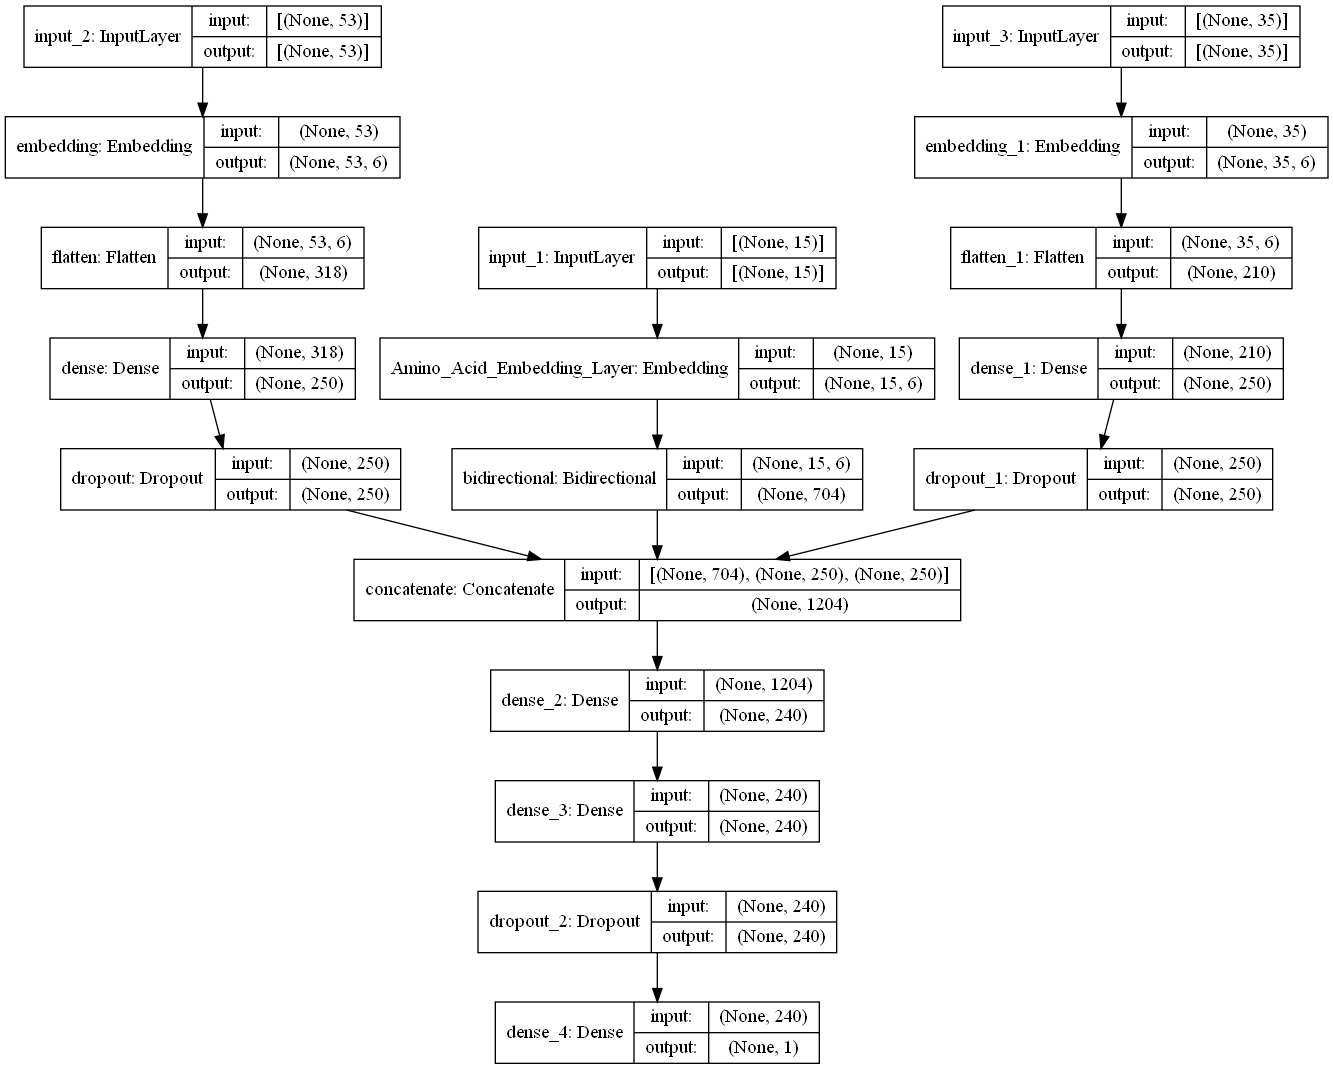

In [25]:
tf.keras.utils.plot_model(m,to_file='model.png', show_shapes=True)

In [15]:
%%time
per_allele_predictions = dict()
for allele_name in ALLELES:
    df = per_allele_val_df[allele_name]
    data = df[['peptide', 'mhc']].to_numpy(dtype=str)
    # Predict binding probability in the pair of a peptide and an MHC allele.
    result = bindingSequencePredictor.predict(peptides=data[:, 0],
                                              alleles=data[:, 1])
    per_allele_predictions[allele_name] = per_allele_val_df[allele_name][['peptide', 'source_sequence_name' ,'binder']].copy()
    per_allele_predictions[allele_name]['score'] = result
    

[[ 0  0  0 ...  5 18  9]
 [ 0  0  1 ... 15 16 15]
 [ 0  0  0 ... 14  1 18]
 ...
 [ 0  0  0 ...  9 10  4]
 [ 0  0  0 ...  9  8  5]
 [ 0  0  0 ... 10 18 15]] [[list([8, 17, 12, 16, 21, 6, 6, 18, 17, 19, 17, 16, 14, 7, 16, 7, 5, 14, 16, 6, 9, 2, 19, 7, 21, 19, 4, 4, 18, 15, 6, 19, 16, 6, 4, 8, 18, 19, 15, 16, 12, 21, 7, 3, 4, 19, 7, 17, 4, 20, 16, 6, 11, 16, 7, 21, 8, 15, 21, 2, 21, 4, 7, 10, 4, 21, 9, 2, 11])
  list([2, 15, 18, 18, 10, 8, 10, 20, 5, 2, 2, 8, 19, 2, 5, 15, 1, 1, 1, 1, 1, 1, 11, 16, 2, 21, 1, 1, 1, 1, 1, 11, 5, 7, 18, 3, 19, 5, 20, 11, 16, 16, 21, 11, 5, 13, 1, 1, 7, 10, 5, 18, 11])
  list([14, 20, 9, 5, 15, 5, 7, 14, 5, 21, 20, 4, 7, 5, 18, 16, 10, 19, 10, 2, 8, 17, 15, 18, 8, 16, 19, 4, 11, 7, 18, 11, 16, 7, 21])]
 [list([8, 17, 12, 16, 21, 6, 6, 18, 17, 19, 17, 16, 14, 7, 16, 7, 5, 14, 16, 6, 9, 2, 19, 7, 21, 19, 4, 4, 18, 15, 6, 19, 16, 6, 4, 8, 18, 19, 15, 16, 12, 21, 7, 3, 4, 19, 7, 17, 4, 20, 16, 6, 11, 16, 7, 21, 8, 15, 21, 2, 21, 4, 7, 10, 4, 21, 9, 2, 11])
  list

#### write to files

In [18]:
from pathlib import Path

# for decoy_key in DECOY_PREFIXES:
Path(TARGET_PATH_TO_PREDICTIONS).mkdir(parents=True, exist_ok=True)
for allele_name, total_df in per_allele_predictions.items():
    total_df.to_csv("{}{}_predictions_{}".format(TARGET_PATH_TO_PREDICTIONS,METHOD,allele_name))

In [19]:
total_df

,peptide,source_sequence_name,binder,score
54615,APAANLASRIPA,seq54615,1,9.999709e-01
54616,APAGPALGL,seq54616,1,1.000000e+00
54617,APAPPPEEVL,seq54617,1,9.999999e-01
54618,APAPPSSGLG,seq54618,1,9.840300e-01
54619,APAPVGPLV,seq54619,1,1.000000e+00
...,...,...,...,...
341347,AYSSPSIV,seq341347,0,2.503647e-05
341348,PPPEVRMTVPPLAT,seq341348,0,1.719556e-04
341349,SEIEDEEEKVSR,seq341349,0,3.546132e-08
341350,RHDSGLDSMKD,seq341350,0,8.694624e-14
